# 05 — Adverse selection

Signed markout at horizon h is `mid(t+h) - mid(fill)` for a buy and the opposite for a sell. Positive is favorable. Future mids are not inputs to the decision.

The session mean pools horizons. This notebook splits them. Orders overlap, so sample size is not an independent-draw count.

markout rows 5136 nulls 0
                 count      mean
side horizon_us                 
buy  5000          869  0.027618
     20000         869  0.461450
     100000        869  0.570771
sell 5000          843 -0.362989
     20000         843 -0.423488
     100000        843 -0.049822
vol_bucket  horizon_us
low         5000         -0.164720
            20000         0.025701
            100000        0.265187


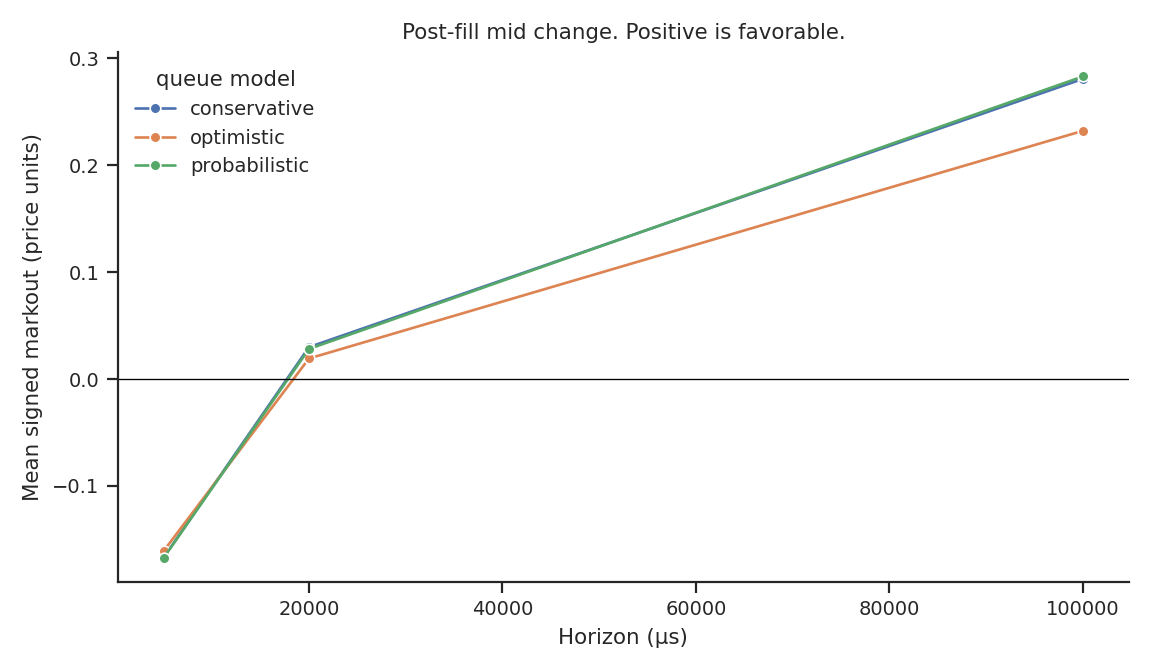

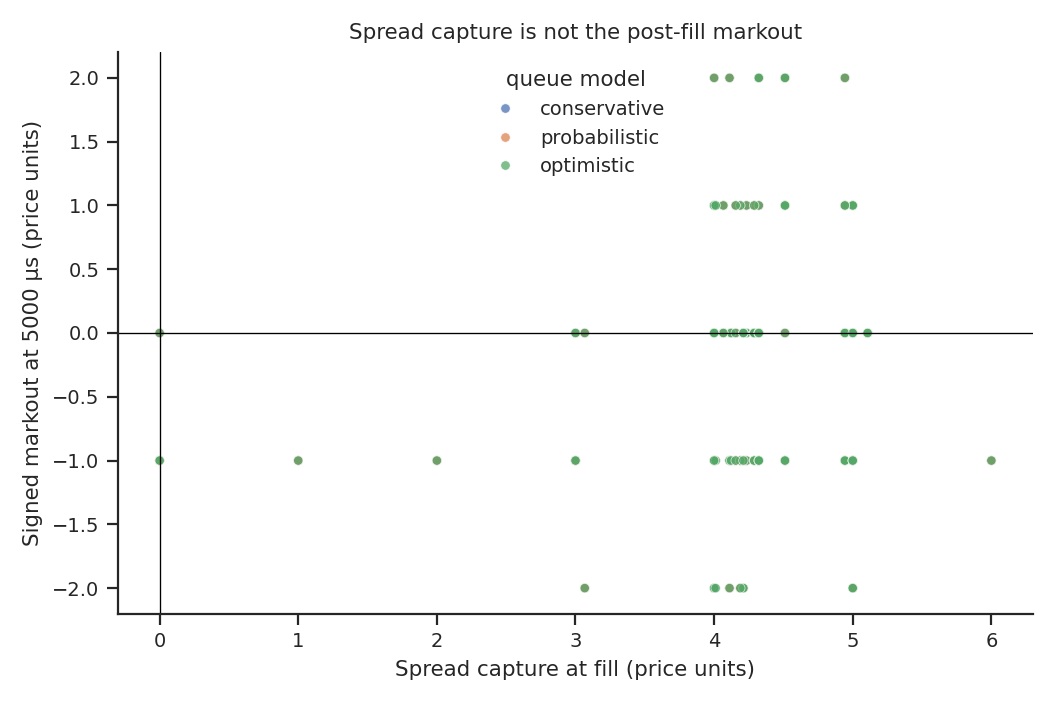

joined points 445


In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd()
if not (ROOT / "scripts" / "analysis.py").is_file():
    raise SystemExit("run this notebook from the repository root")
sys.path.insert(0, str(ROOT / "scripts"))
import analysis
from IPython.display import Image, display

def show(name):
    display(Image(filename=str(analysis.FIG / f"{name}.png")))

marks = analysis.markouts()
execs = analysis.executions()
print("markout rows", len(marks), "nulls", int(marks["signed_markout"].isna().sum()))
print(marks.groupby(["side", "horizon_us"])["signed_markout"].agg(["count", "mean"]).to_string())
print(marks.groupby(["vol_bucket", "horizon_us"])["signed_markout"].mean().to_string())
analysis.plot_markout_horizons(marks, analysis.FIG)
show("markout_horizons")
joined = analysis.plot_capture_vs_markout(execs, marks, analysis.FIG)
show("capture_vs_markout")
print("joined points", len(joined))


A fill can show positive spread capture and negative markout at the same time. Net cash outcome also subtracts the modeled fee inside the ledger. The scatter does not add that fee a second time.